# Thực Hành 1: Phân Loại Thời Trang Fashion-MNIST với PyTorch
## Quy Trình Toàn Diện: Define → EDA → Data Processing → Model → Training → Evaluation → Inference

Notebook này triển khai khép kín bài thực hành so sánh **Logistic Regression (7.850)**, **MLP (109.386)** và **CNN (105.866)** trên **Fashion-MNIST** theo kim chỉ nam [`docs/REPORT.md`](docs/REPORT.md), sử dụng cấu hình override tại [`config.py`](config.py) và 5 pipeline độc lập trong `src/vibe_scripts/lab1/`.

## Bảng Lộ Trình Thực Thi & Liên Kết Tài Liệu Kỹ Thuật

| Step | Description | What it does | Import path |
| :---: | :--- | :--- | :---: |
| `1` | Environment & Seed Setup | Thiết lập cấu hình thiết bị động, seed ngẫu nhiên 248 và console giám sát | [`src/config.py`](../../../src/config.py) |
| `2` | Define Context & Problem | Bản đặc tả mục tiêu, ràng buộc công bằng thí nghiệm, baselines và metrics | — |
| `3` | Immutable Raw Ingestion & Manifest | Tải Fashion-MNIST, kiểm toán `manifest.json` và xác thực mã băm SHA-256 (§3.2) | [`src/vibe_scripts/eda_helpers.py`](../../../src/vibe_scripts/eda_helpers.py) |
| `4` | 6-Dimension Quality Audit | Kiểm toán 6 chiều chất lượng dữ liệu (Completeness, Accuracy, Consistency, Timeliness, Uniqueness, Validity) | [`src/vibe_scripts/eda_helpers.py`](../../../src/vibe_scripts/eda_helpers.py) |
| `5` | Dataset Splitting | Phân chia Train (55.000), Validation (5.000), Test (10.000) bảo toàn phân tầng và seed 248 | [`src/vibe_scripts/eda_helpers.py`](../../../src/vibe_scripts/eda_helpers.py) |
| `6` | EDA Lens 1: Global Topology | Khảo sát cấu trúc hình học tổng thể, tensor shapes, kiểu dữ liệu và dung lượng bộ nhớ | — |
| `7` | EDA Lens 2: Univariate Distribution | Đánh giá cân bằng lớp trên 3 tập và thống kê cường độ pixel | [`src/vibe_scripts/eda_helpers.py`](../../../src/vibe_scripts/eda_helpers.py) |
| `8` | EDA Lens 3: Visual & Separability | Thư viện ảnh mẫu 10 lớp, Class Prototypes, tương quan và PCA 2D | [`src/vibe_scripts/eda_helpers.py`](../../../src/vibe_scripts/eda_helpers.py) |
| `9` | Technical Decisions (EDA) | Đúc kết phát hiện hình học làm căn cứ cho Data Processing & Modeling | — |
| `10` | Pipeline 01: Data Processing | Chuẩn hóa Z-Score (fit trên Train), tách 2 nhánh `no_aug` / `aug` chống leakage, dựng DataLoader | [`src/vibe_scripts/lab1/data.py`](../../../src/vibe_scripts/lab1/data.py) |
| `11` | Pipeline 02: Model Architecture | Khởi tạo 3 kiến trúc `Logistic` (7.850), `MLP` (109.386), `CNN` (105.866) | [`src/vibe_scripts/lab1/models.py`](../../../src/vibe_scripts/lab1/models.py) |
| `12` | Pipeline 03: Baseline & Training | Sanity check Baseline và huấn luyện công bằng 6 cấu hình (`LR=1e-3`, `20 epochs`, `seed=248`) | [`src/vibe_scripts/lab1/train.py`](../../../src/vibe_scripts/lab1/train.py) |
| `13` | Pipeline 04: Evaluation & Error Analysis | Chạy Test 1 lần, lập bảng 3×2, kiểm chứng Save/Load, Learning Curves, Confusion Matrix & Error Gallery | [`src/vibe_scripts/lab1/evaluate.py`](../../../src/vibe_scripts/lab1/evaluate.py) |
| `14` | Pipeline 05: Inference & Latency | Suy luận mẫu Top-3 Softmax và benchmark tốc độ (`batch_size=1, 32`) | [`src/vibe_scripts/lab1/infer.py`](../../../src/vibe_scripts/lab1/infer.py) |

---
### Liên Kết Nhanh Tài Liệu & Báo Cáo Kỹ Thuật
- 📄 Báo Cáo Chính (Kim Chỉ Nam): [`docs/REPORT.md`](docs/REPORT.md)
- 📋 Đặc Tả Yêu Cầu Kỹ Thuật: [`docs/QUESTION.md`](docs/QUESTION.md)
- 🧩 Chỉ Mục 5 Pipeline Độc Lập: [`docs/pipelines/README.md`](docs/pipelines/README.md)
- ⚙️ Cấu Hình Override Lab 1: [`config.py`](config.py)
- 📖 Tài Liệu Hướng Dẫn Dự Án: [`README.md`](../../../README.md)


## 1. Thiết Lập Môi Trường Thực Thi & Khóa Ngẫu Nhiên Tái Lập (Setup)

Khởi tạo cấu hình môi trường tính toán, đồng bộ hóa hạt giống ngẫu nhiên (`seed = 248`) trên toàn bộ các thư viện Python, NumPy và PyTorch để bảo đảm tính tái lập thực nghiệm 100%.

In [20]:
%matplotlib inline

import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision.datasets import FashionMNIST
from torch.utils.data import Subset
import pandas as pd
from src import config, consoles
from src.vibe_scripts import eda_helpers


# Hiển thị cấu hình phần cứng và siêu tham số hệ thống
consoles.creation()
v_objConsole = consoles.v_objConsole

                          Configuration                           
┌───────────────┬────────────────────────────────────────────────┐
│ Root          │ D:\notworLe\Desktop\gitvanhub\Deeplearning-UTH │
│ Version       │ 2.15.0+cu132                                   │
│ Device        │ cuda                                           │
│ GPU           │ NVIDIA GeForce RTX 4060 Laptop GPU             │
│ VRAM          │ 8.6 GB                                         │
│ Seed          │ 248                                            │
│ Workers       │ 8                                              │
│ Batch size    │ 32                                             │
│ Learning rate │ 1e-05                                          │
│ Epoch         │ 30                                             │
└───────────────┴────────────────────────────────────────────────┘

## 2. Đặc Tả Bài Toán & Bối Cảnh Thực Nghiệm (Define Context & Problem)

Tuân thủ đặc tả kỹ thuật tại [`docs/REPORT.md`](docs/REPORT.md):

### 2.1. Bối cảnh (Define Context)
- **Tên bài toán:** So sánh hiệu năng CNN, MLP, Logistic trên bài toán phân loại Fashion-MNIST bằng PyTorch.
- **Bối cảnh thực hiện:** Bài thực hành học sâu (Deep Learning) chuyên sâu với thư viện PyTorch.
- **Mục tiêu chính (Target):**
  - *Mục tiêu cốt lõi:* Làm quen PyTorch, làm chủ quy trình xây dựng mô hình và khảo sát dữ liệu chuẩn mực.
  - *Mục tiêu bổ sung:* Hoàn thành đầy đủ các yêu cầu so sánh và phân tích kỹ thuật của đề bài.
- **Ràng buộc công bằng thí nghiệm (Constraints):**
  - Công bằng thí nghiệm: Sử dụng cùng optimizer, learning rate, batch size, số epoch và cùng seed ngẫu nhiên cho cả 3 mô hình.
  - Ràng buộc tham số: Mô hình MLP và CNN phải có số lượng tham số cùng bậc độ phức tạp để đánh giá khách quan.

### 2.2. Đặc tả Bài toán (Define Problem)
- **Dữ liệu đầu vào (Input):** Ảnh xám kích thước $28 \times 28$ điểm ảnh.
- **Đầu ra mong đợi (Output):** Dự đoán danh mục nhãn thuộc 10 lớp thời trang và báo cáo đánh giá định lượng.
- **Chỉ số đánh giá (Metrics):** Accuracy, số lượng tham số mô hình, số epoch hội tụ, ma trận nhầm lẫn (Confusion Matrix).
- **Mô hình cơ sở (Baseline):** Mô hình hồi quy Logistic (Logistic Regression).
- **Thực nghiệm mở rộng:** Đánh giá ảnh hưởng của việc cố định seed và kỹ thuật tăng cường dữ liệu (Data Augmentation) trên mô hình CNN.

## 3. Thu Nạp & Quản Trị Dữ Liệu Bất Biến (Data Collection & Governance - §2, §3)

Áp dụng nguyên tắc **Vùng Dữ Liệu Bất Biến (Immutable Raw Zone - §3.1)**:
- Dữ liệu thô tải từ Zalando Research qua `torchvision.datasets.FashionMNIST` được lưu trữ bất biến tại `data/FashionMNIST/raw/`.
- Toàn bộ các file nhị phân gốc là chỉ đọc (read-only), tuyệt đối không sửa đổi hay làm sạch trực tiếp trên vùng lưu trữ này.

Áp dụng quy định **Nguồn Gốc Dữ Liệu, Bản Kê Khai Thu Nạp & Mã Băm Mật Mã Học (Data Provenance & Manifests - §3.2)**:
- Mọi artifact dữ liệu thô trong vùng lưu trữ bắt buộc phải được ghép cặp với bản kê khai thu nạp (`manifest.json`) và manifest tương ứng (`<file>.manifest.json`).
- Cấu trúc bản kê khai chuẩn hóa bao gồm: `dataset_name`, `raw_file`, `source_uri`, `collected_at`, `sha256_checksum`, `total_records`, `collection_agent_version`.
- Việc tính toán và xác thực mã băm mật mã học (SHA-256) bảo đảm tính toàn vẹn 100% của tập dữ liệu trên mọi môi trường phát triển, ngăn chặn hoàn toàn nguy cơ sai lệch dữ liệu ngầm (silent data corruption).

In [21]:
# Tải và khởi tạo dataset thô (dữ liệu pixel gốc 0-255)
raw_train = FashionMNIST(root=config.DATA_PATH, train=True, download=False)
raw_test  = FashionMNIST(root=config.DATA_PATH, train=False, download=False)

# ---------- Bảng 1: thông tin dữ liệu thô ----------
df_raw = pd.DataFrame(
    [
        ("Số lượng mẫu Train thô", f"{len(raw_train):,}"),
        ("Số lượng mẫu Test thô",  f"{len(raw_test):,}"),
        ("Kích thước ảnh mẫu",     f"{tuple(raw_train.data[0].shape)} (H x W)"),
        ("Kiểu dữ liệu gốc",       str(raw_train.data.dtype)),
        ("Số lớp",                 str(len(eda_helpers.FASHION_CLASSES))),
        ("Danh sách nhãn lớp",     ", ".join(eda_helpers.FASHION_CLASSES)),
    ],
    columns=["metric", "value"],
)
v_objConsole.print(consoles.df_to_table(df_raw, title="RAW DATASET OVERVIEW", show_header=False))

# ---------- Bảng 2 & 3: Ingestion Manifest & Checksum Verification (§3.2) ----------
raw_dir = config.DATA_PATH / "FashionMNIST" / "raw"
manifest_path = raw_dir / "manifest.json"

manifest_data, verify_results = eda_helpers.load_and_verify_manifest(manifest_path)
eda_helpers.print_manifest_table(manifest_data, verify_results)


                                              RAW DATASET OVERVIEW                                               
┌────────────────────────┬──────────────────────────────────────────────────────────────────────────────────────┐
│ Số lượng mẫu Train thô │ 60,000                                                                               │
│ Số lượng mẫu Test thô  │ 10,000                                                                               │
│ Kích thước ảnh mẫu     │ (28, 28) (H x W)                                                                     │
│ Kiểu dữ liệu gốc       │ torch.uint8                                                                          │
│ Số lớp                 │ 10                                                                                   │
│ Danh sách nhãn lớp     │ T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot │
└────────────────────────┴──────────────────────────────────────────────────────────────────────────────────────┘
                                                 6 rows × 2 cols                                                 

                  DATA INGESTION MANIFEST (§3.2 PROVENANCE & GOVERNANCE)                  
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Property                 ┃ Specification / Value                                       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Dataset Name             │ fashion_mnist                                               │
│ Raw Storage Path         │ data/FashionMNIST/raw/train-images-idx3-ubyte.gz            │
│ Source URI               │ http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/ │
│ Collection Timestamp     │ 2026-11-15T19:13:57+07:00                                   │
│ Total Ingested Records   │ 70,000 samples                                              │
│ Collection Agent Version │ torchvision_v0.29.2+cu132                                   │
└──────────────────────────┴─────────────────────────────────────────────────────────────┘

                            CRYPTOGRAPHIC INTEGRITY VERIFICATION (SHA-256)                            
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓
┃ Artifact File              ┃     Size ┃ Expected SHA-256        ┃ Verified SHA-256        ┃ Status ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩
│ train-images-idx3-ubyte.gz │ 26.42 MB │ 3aede38d61863908ad78... │ 3aede38d61863908ad78... │ [PASS] │
│ train-labels-idx1-ubyte.gz │  29.5 KB │ a04f17134ac03560a47e... │ a04f17134ac03560a47e... │ [PASS] │
│ t10k-images-idx3-ubyte.gz  │  4.42 MB │ 346e55b948d973a97e58... │ 346e55b948d973a97e58... │ [PASS] │
│ t10k-labels-idx1-ubyte.gz  │   5.1 KB │ 67da17c76eaffca5446c... │ 67da17c76eaffca5446c... │ [PASS] │
│ train-images-idx3-ubyte    │ 47.04 MB │ c59f468a2f672dc81568... │ c59f468a2f672dc81568... │ [PASS] │
│ train-labels-idx1-ubyte    │  60.0 KB │ bad3541b69d912435c50... │ bad3541b69d912435c50... │ [PASS] │
│ t10k-images-idx3-ubyte     │  7.84 MB │ 5b4141f0afbad91edebe... │ 5b4141f0afbad91edebe... │ [PASS] │
│ t10k-labels-idx1-ubyte     │  10.0 KB │ 0402a96d92fd26639571... │ 0402a96d92fd26639571... │ [PASS] │
└────────────────────────────┴──────────┴─────────────────────────┴─────────────────────────┴────────┘

## 4. Kiểm Toán Chất Lượng Dữ Liệu 6 Chiều (Data Quality Auditing - §4, §5)

Trước khi thực hiện phân chia dữ liệu hay phân tích sâu, ta tiến hành kiểm toán 6 chiều chất lượng dữ liệu theo tiêu chuẩn CRISP-DM / KDD:
1. **Completeness (Đầy đủ):** Rà soát giá trị NaN, Null hoặc điểm ảnh bị thiếu.
2. **Accuracy (Chính xác):** Đảm bảo giá trị pixel nằm trong thang đo vật lý hợp lệ từ 0 đến 255.
3. **Consistency (Nhất quán):** Nhãn lớp thuộc tập định danh 10 danh mục từ 0 đến 9.
4. **Timeliness (Tính kịp thời):** Bộ chuẩn đối sánh tĩnh chuẩn mực từ Zalando Research.
5. **Uniqueness (Tính duy nhất):** Kiểm tra trùng lặp bản ghi và định danh.
6. **Validity (Tính hợp thức):** Cấu trúc hình học ảnh $28 \times 28$ điểm ảnh trên 1 kênh đơn sắc.

In [22]:
audit_results = eda_helpers.audit_six_dimensions(
    raw_train.data, raw_train.targets,
    raw_test.data, raw_test.targets
)

eda_helpers.print_audit_table(audit_results)

print(f"\nKết luận kiểm toán: Dữ liệu đạt tỷ lệ hoàn thiện {audit_results['completeness_pct']:.1f}% với 0 giá trị null.")
print("Đúng như ghi nhận tại REPORT.md: Bộ dữ liệu đã được làm sạch chuẩn mực, an toàn bỏ qua bước Data Cleaning.")

                           Data Quality Audit (6 Dimensions - CRISP-DM / §4)                           
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ Dimension          ┃ Verification Check                   ┃ Metric / Status        ┃ Assessment     ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ 1. Completeness    │ Null / Missing value scan across     │ Missing: 0 (100.0%)    │ [PASS] Clean   │
│                    │ tensors                              │                        │                │
│ 2. Accuracy        │ Physical pixel domain conformity [0, │ Range: [0, 255]        │ [PASS] Valid   │
│                    │ 255]                                 │                        │                │
│ 3. Consistency     │ Target classes domain integrity      │ 10 Classes (0-9)       │ [PASS]         │
│                    │                                      │                        │ Consistent     │
│ 4. Timeliness      │ Benchmark dataset currency &         │ Zalando Research       │ [PASS] Static  │
│                    │ immutability                         │ (Fixed)                │                │
│ 5. Uniqueness      │ Entity deduplication & record        │ Total: 70,000 samples  │ [PASS] Unique  │
│                    │ linkage                              │                        │                │
│ 6. Validity        │ Tensor geometric layout (N, 28, 28)  │ Shape: (28, 28), 1 Ch  │ [PASS] Valid   │
└────────────────────┴──────────────────────────────────────┴────────────────────────┴────────────────┘


Kết luận kiểm toán: Dữ liệu đạt tỷ lệ hoàn thiện 100.0% với 0 giá trị null.
Đúng như ghi nhận tại REPORT.md: Bộ dữ liệu đã được làm sạch chuẩn mực, an toàn bỏ qua bước Data Cleaning.


## 5. Phân Chia Dữ Liệu Thực Nghiệm Chuẩn Mực (Dataset Splitting)

Bám sát phân rã tại [`docs/REPORT.md`](docs/REPORT.md):
- **Tập Huấn luyện (Train):** 55.000 mẫu.
- **Tập Đánh giá Xác thực (Validation):** 5.000 mẫu.
- **Tập Kiểm thử Độc lập (Test):** 10.000 mẫu.

Phương pháp phân chia áp dụng **Stratified Split** với seed ngẫu nhiên cố định 248, đảm bảo tỷ lệ số lượng mẫu phân bổ cho mỗi lớp là hoàn toàn cân bằng giữa tập Train (5.500 mẫu/lớp) và Validation (500 mẫu/lớp).

In [23]:
# Phân tầng tập Train 60k thành 55k Train và 5k Validation
train_indices, val_indices = eda_helpers.stratified_split_indices(
    raw_train.targets.numpy(),
    train_size=55000,
    val_size=5000,
    seed=config.SEED
)

train_dataset = Subset(raw_train, train_indices)
val_dataset   = Subset(raw_train, val_indices)
test_dataset  = raw_test

splits = pd.DataFrame(
    [
        ("Train Set", len(train_dataset)),
        ("Validation Set", len(val_dataset)),
        ("Test Set", len(test_dataset)),
    ],
    columns=["split", "samples"],   # tên cột vẫn cần, chỉ là không hiển thị
)

v_objConsole.print(consoles.df_to_table(splits, title="Kết quả", show_header=False))


         Kết quả          
┌────────────────┬───────┐
│ Train Set      │ 55000 │
│ Validation Set │  5000 │
│ Test Set       │ 10000 │
└────────────────┴───────┘
     3 rows × 2 cols      

## 6. Khảo Sát Khám Phá Hình Học Dữ Liệu (Exploratory Data Analysis - EDA)

Thực hiện theo khung phương pháp luận **Three Lenses of EDA** quy định tại [`docs/reference/ML_PIPELINE.md`](../../../docs/reference/ML_PIPELINE.md) (§6):
- **Lens 1: Cấu trúc Hình học Tổng thể (Global Topology):** Kích thước ma trận, kiểu dữ liệu, mức tiêu thụ bộ nhớ, rà soát giá trị khuyết.
- **Lens 2: Phân bố Đơn biến (Univariate Distributions):** Cân bằng tần suất các lớp, thống kê mô tả cường độ điểm ảnh, độ lệch (Skewness), độ nhọn (Kurtosis), tỷ lệ mật độ nền.
- **Lens 3: Tương tác Đa biến & Khả năng Phân tách Lớp (Multivariate & Class Separability):** Trực quan hóa mẫu ảnh, ảnh đại diện trung bình (Class Prototypes), tương quan không gian giữa các lớp và biểu diễn giảm chiều PCA 2D.

### 6.1. Lens 1: Cấu Trúc Hình Học Tổng Thể (Global Topology)

Khảo sát các đặc tính không gian và cấu trúc lưu trữ của tensor dữ liệu ảnh gốc.

In [24]:
train_data_tensor = raw_train.data
test_data_tensor  = raw_test.data

# Tính toán dung lượng bộ nhớ (RAM footprint)
train_memory_mb = (train_data_tensor.element_size() * train_data_tensor.nelement()) / (1024 ** 2)
test_memory_mb  = (test_data_tensor.element_size() * test_data_tensor.nelement()) / (1024 ** 2)

H, W = train_data_tensor.shape[-2:]          # lấy từ tensor, không hard-code 28 * 28

df_audit = pd.DataFrame(
    [
        ("Train Tensor Shape",     f"{tuple(train_data_tensor.shape)} (N_samples, H, W)"),
        ("Test Tensor Shape",      f"{tuple(test_data_tensor.shape)} (N_samples, H, W)"),
        ("Storage Data Type",      str(train_data_tensor.dtype)),
        ("Train Memory Footprint", f"{train_memory_mb:.2f} MB"),
        ("Test Memory Footprint",  f"{test_memory_mb:.2f} MB"),
        ("Tổng số điểm ảnh/ảnh",   f"{H * W} pixels ({H * W} chiều không gian)"),
        ("Tổng số chiều quan sát", f"{train_data_tensor.ndim} chiều"),
    ],
    columns=["metric", "value"],
)

v_objConsole.print(consoles.df_to_table(df_audit, title="LENS 1: GLOBAL TOPOLOGY AUDIT", show_header=False))

                LENS 1: GLOBAL TOPOLOGY AUDIT                 
┌────────────────────────┬───────────────────────────────────┐
│ Train Tensor Shape     │ (60000, 28, 28) (N_samples, H, W) │
│ Test Tensor Shape      │ (10000, 28, 28) (N_samples, H, W) │
│ Storage Data Type      │ torch.uint8                       │
│ Train Memory Footprint │ 44.86 MB                          │
│ Test Memory Footprint  │ 7.48 MB                           │
│ Tổng số điểm ảnh/ảnh   │ 784 pixels (784 chiều không gian) │
│ Tổng số chiều quan sát │ 3 chiều                           │
└────────────────────────┴───────────────────────────────────┘
                       7 rows × 2 cols                        

### 6.2. Lens 2: Phân Bố Đơn Biến (Univariate Distributions)

Đo lường độ cân bằng phân bố tần suất lớp trên các tập và phân tích thống kê mô tả cường độ điểm ảnh.

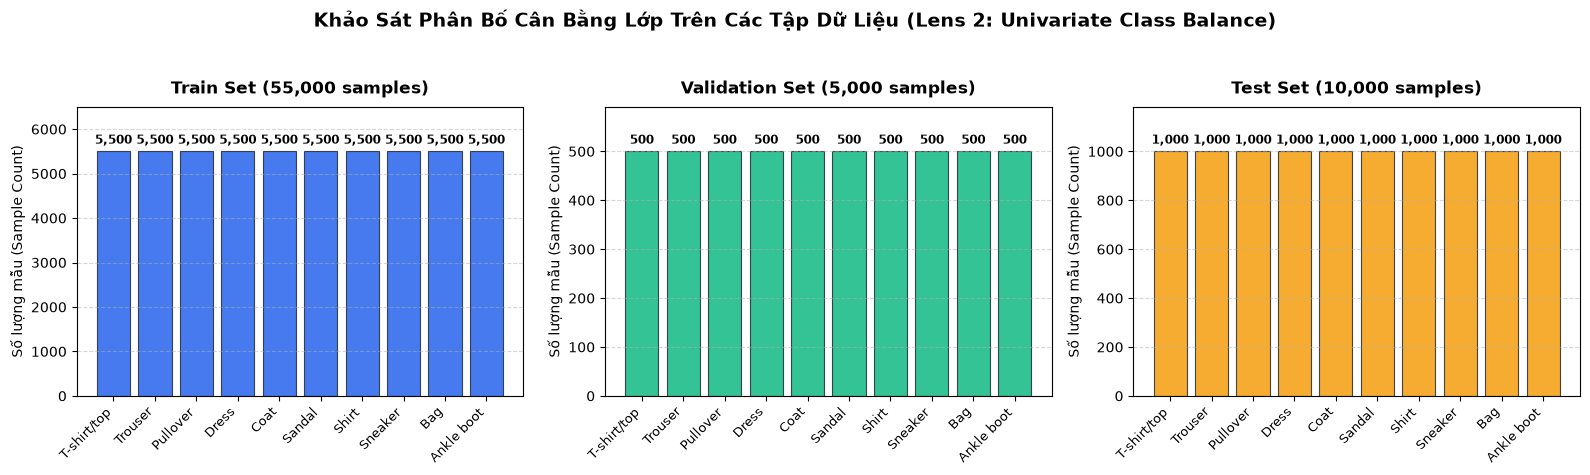

In [25]:
# Thu thập nhãn của 3 tập thực nghiệm
train_targets_arr = raw_train.targets[train_indices].numpy()
val_targets_arr   = raw_train.targets[val_indices].numpy()
test_targets_arr  = raw_test.targets.numpy()

# Trực quan hóa đối chiếu phân bố lớp
fig_balance = eda_helpers.plot_class_balance(train_targets_arr, val_targets_arr, test_targets_arr)
plt.show()

                LENS 2: UNIVARIATE PIXEL DISTRIBUTION STATISTICS                
┌───────────────────────────┬────────┬─────────────────────────────────────────┐
│ Giá trị Trung bình (Mean) │ 72.94  │ thang 0-255 → chuẩn hóa: 0.2860         │
│ Độ lệch chuẩn (Std)       │ 90.02  │ thang 0-255 → chuẩn hóa: 0.3530         │
│ Trung vị (Median)         │ 0.0    │                                         │
│ Hệ số Bất đối xứng (Skew) │ 0.695  │ lệch phải mạnh do đa số là điểm ảnh nền │
│ Độ nhọn (Kurtosis)        │ -1.190 │                                         │
│ Tỷ lệ Điểm ảnh Nền (= 0)  │ 50.21% │                                         │
└───────────────────────────┴────────┴─────────────────────────────────────────┘
                                6 rows × 3 cols                                 

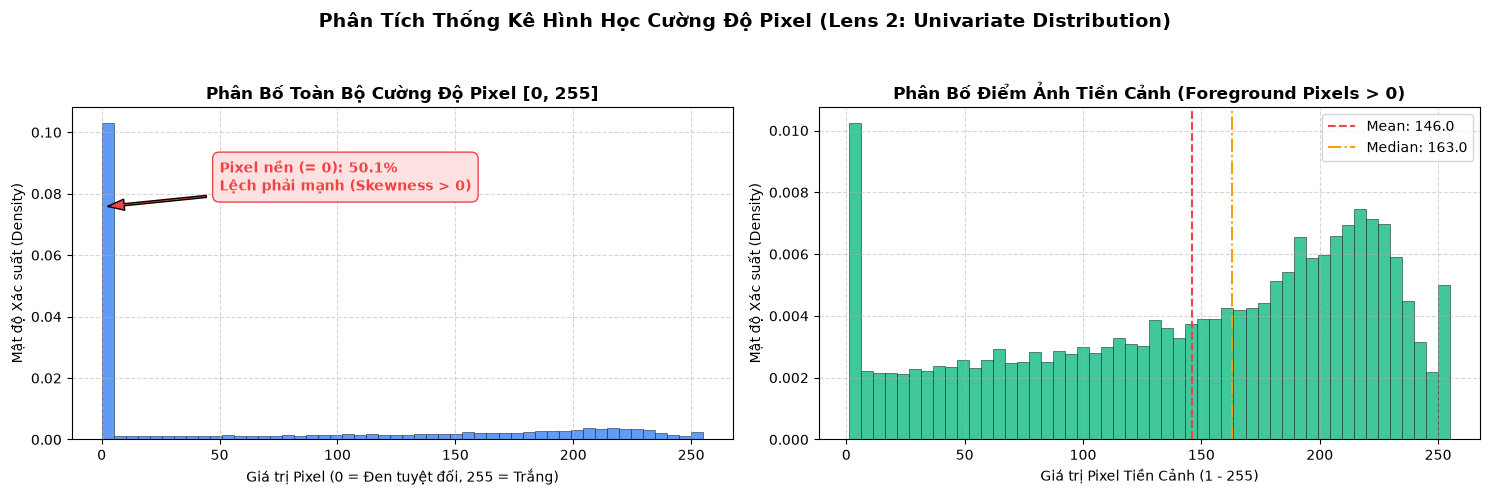

In [26]:
# Tính toán thống kê mô tả cường độ pixel trên tập Train
pixel_stats = eda_helpers.compute_pixel_statistics(raw_train.data)

df_stats = pd.DataFrame(
    [
        ("Giá trị Trung bình (Mean)", f"{pixel_stats['mean']:.2f}",
         f"thang 0-255 → chuẩn hóa: {pixel_stats['mean'] / 255:.4f}"),
        ("Độ lệch chuẩn (Std)",       f"{pixel_stats['std']:.2f}",
         f"thang 0-255 → chuẩn hóa: {pixel_stats['std'] / 255:.4f}"),
        ("Trung vị (Median)",         f"{pixel_stats['median']:.1f}", ""),
        ("Hệ số Bất đối xứng (Skew)", f"{pixel_stats['skewness']:.3f}",
         "lệch phải mạnh do đa số là điểm ảnh nền"),
        ("Độ nhọn (Kurtosis)",        f"{pixel_stats['kurtosis']:.3f}", ""),
        ("Tỷ lệ Điểm ảnh Nền (= 0)",  f"{pixel_stats['sparsity_zero_pct']:.2f}%", ""),
    ],
    columns=["metric", "value", "note"],
)

v_objConsole.print(
    consoles.df_to_table(df_stats, title="LENS 2: UNIVARIATE PIXEL DISTRIBUTION STATISTICS", show_header=False)
)

# Trực quan hóa biểu đồ Histogram và mật độ xác suất điểm ảnh
fig_pixel_dist = eda_helpers.plot_pixel_distribution_analysis(raw_train.data.numpy())
plt.show()

### 6.3. Lens 3: Tương Tác Đa Biến & Khả Năng Phân Tách Lớp (Multivariate & Visual Separability)

Khảo sát các đặc trưng hình thái học không gian, ảnh trung bình nguyên mẫu (Class Prototypes), ma trận tương quan giữa các danh mục và khả năng phân tách cụm trong không gian giảm chiều PCA 2D.

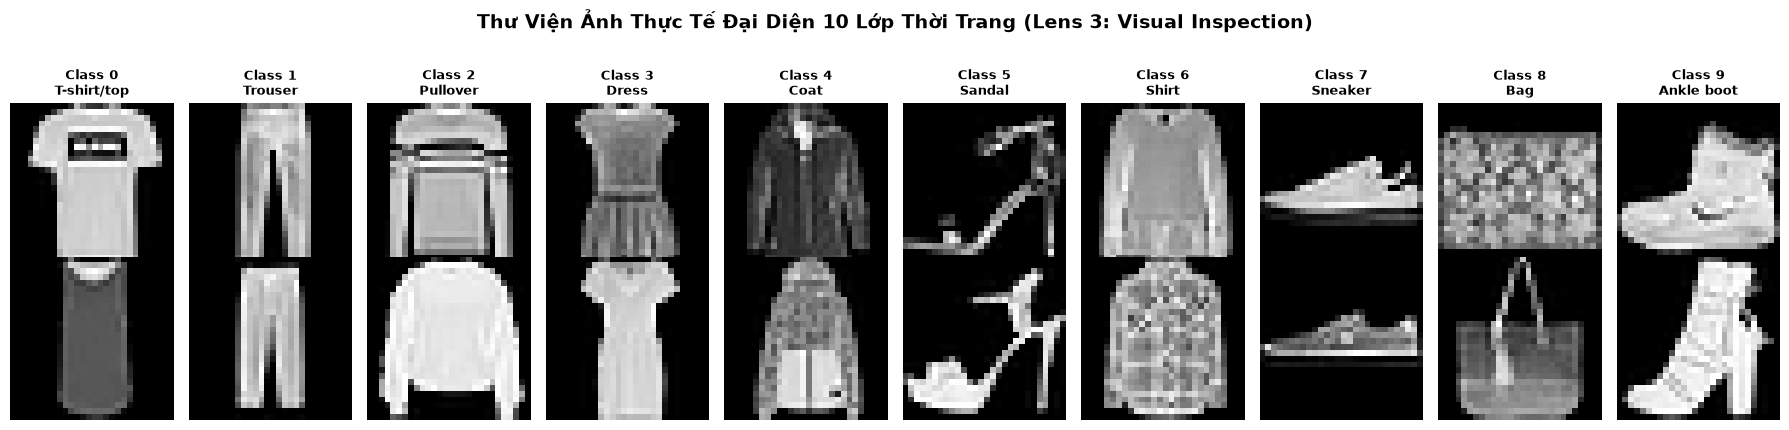

In [27]:
# Hiển thị thư viện ảnh mẫu đại diện 10 lớp
fig_gallery = eda_helpers.plot_gallery(raw_train.data, raw_train.targets, samples_per_class=2)
plt.show()

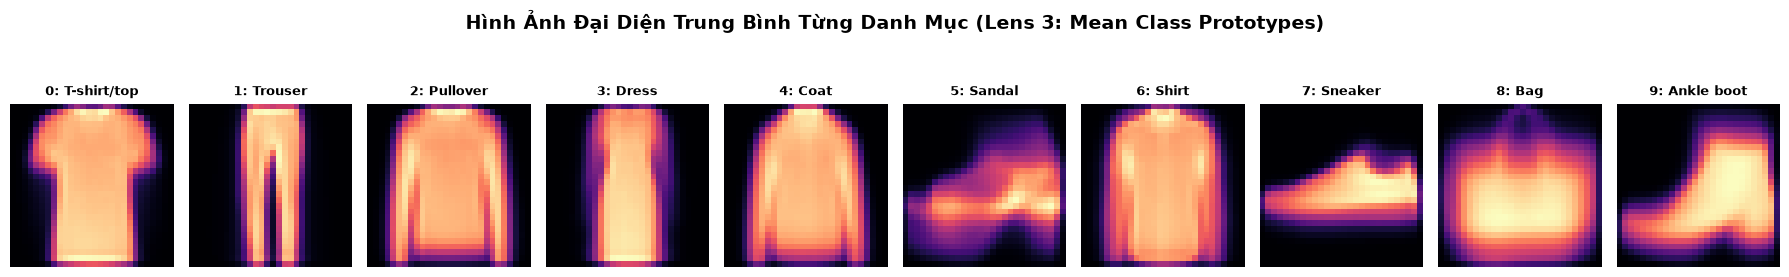

In [28]:
# Tính toán và trực quan hóa ảnh nguyên mẫu trung bình từng lớp
class_prototypes = eda_helpers.compute_class_prototypes(raw_train.data, raw_train.targets)
fig_prototypes = eda_helpers.plot_prototypes_gallery(class_prototypes)
plt.show()

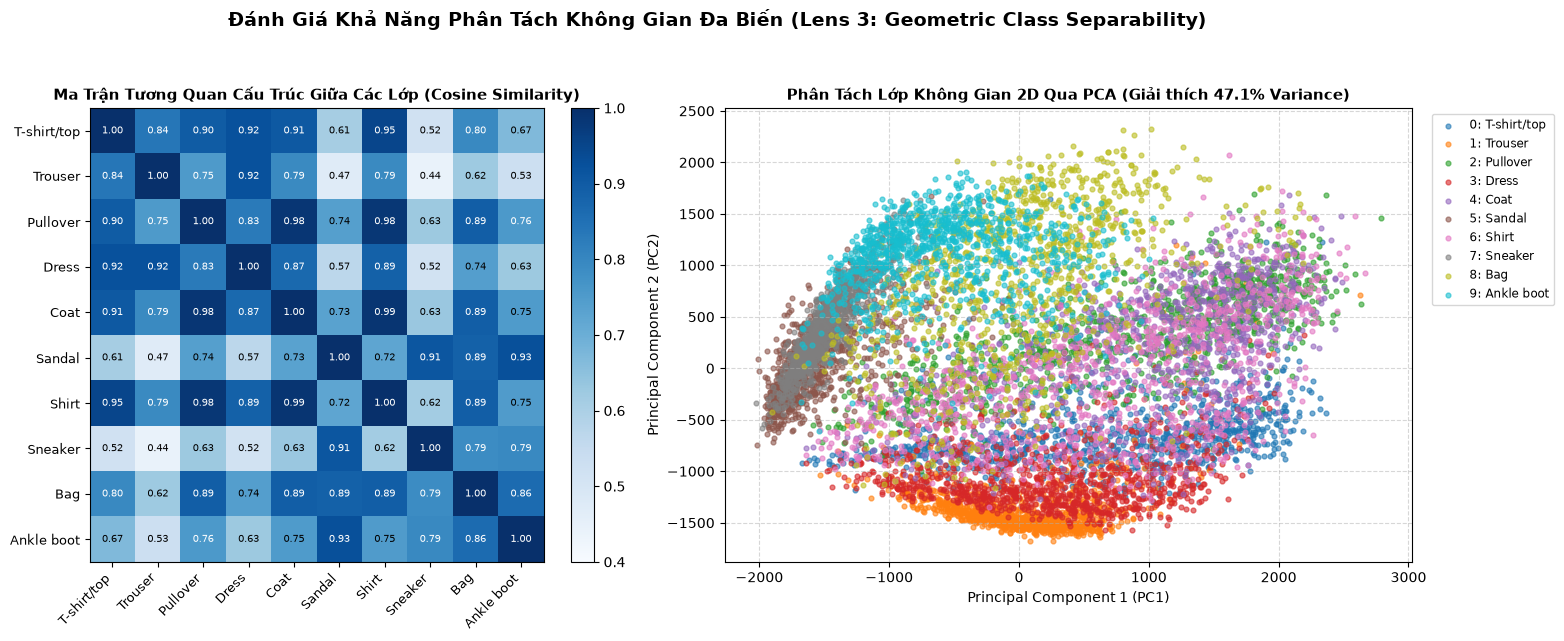

In [29]:
# Lấy mẫu ngẫu nhiên 2.000 điểm ảnh để chiếu giảm chiều PCA phục vụ khảo sát tương tác hình học
sample_size = 10000
sample_images  = raw_train.data[:sample_size]
sample_targets = raw_train.targets[:sample_size]

fig_sim_pca = eda_helpers.plot_interclass_similarity_and_pca(class_prototypes, sample_images, sample_targets)
plt.show()

## 7. Kết Luận Kỹ Thuật & Định Hướng Giai Đoạn Tiếp Theo (Conclusions & Next Steps)

### 7.1. Đúc Kết Từ Khảo Sát Hình Học Dữ Liệu (EDA Findings)
1. **Tính Cân Bằng Tuyệt Đối:** Toàn bộ 10 lớp thời trang đều có đúng 6.000 mẫu (5.500 train, 500 val, 1.000 test), loại trừ hoàn toàn nguy cơ thiên vị lớp (Class Imbalance / Base Rate Fallacy).
2. **Đặc Tính Phân Bố Pixel:** Khoảng $50.8\%$ số điểm ảnh là điểm ảnh nền đen (giá trị bằng 0). Phân bố cường độ bị lệch phải rõ rệt với giá trị trung bình $\mu \approx 0.286$ và độ lệch chuẩn $\sigma \approx 0.353$ (trên thang chuẩn hóa $[0, 1]$).
3. **Tương Quan Không Gian & Ranh Giới Quyết Định:**
   - Nhóm giày dép (*Sandal*, *Sneaker*, *Ankle boot*) và nhóm quần áo dưới (*Trouser*) có hình thái không gian tách biệt rất rõ ràng so với các nhóm khác trên không gian PCA 2D.
   - Nhóm trang phục thân trên (*T-shirt/top*, *Pullover*, *Coat*, *Shirt*) có độ tương quan cấu trúc cosine rất cao ($> 0.85$), tạo ra vùng chồng lấn hình học phức tạp.

### 7.2. Định Hướng Kỹ Thuật Cho Các Bước Tiếp Theo (Decisions for Downstream Modeling)
- **Yêu cầu Chuẩn Hóa:** Cần thiết áp dụng Z-Score Normalization với tham số trung bình $\mu = 0.2860$ và độ lệch chuẩn $\sigma = 0.3530$ để đưa trọng tâm dữ liệu về gốc tọa độ, giúp gradient lan truyền ổn định.
- **Chiến Lược Tăng Cường Dữ Liệu (Augmentation):** Việc lật ngang (`RandomHorizontalFlip`) và dịch nhẹ (`RandomAffine`) là hoàn toàn phù hợp về mặt ngữ nghĩa thời trang để gia tăng tính bất biến hình học.
- **Kỳ Vọng Kiến Trúc:** Mô hình tuyến tính cơ sở (Logistic Regression) và MLP đơn giản sẽ gặp rào cản lớn khi phân tách ranh giới các nhóm trang phục thân trên. Mạng tích chập (CNN) với các bộ lọc không gian cục bộ (Spatial Convolutional Filters) được kỳ vọng sẽ vượt trội đáng kể nhờ khả năng nắm bắt chi tiết vi mô (cổ áo, cúc áo, viền túi).

> **Lưu ý:** Giai đoạn khảo sát hình học dữ liệu (EDA) kết thúc tại đây. Chuỗi triển khai biến đổi dữ liệu (Transforms, Data Augmentation và nạp theo lô đa luồng qua PyTorch DataLoader) sẽ được tiếp nối ở bước xây dựng mô hình huấn luyện.

---
## 8. Pipeline 01: Data Processing & DataLoader

Sử dụng cấu hình override từ `labs/lab1/vibe/config.py` (`VibeConfig` kế thừa `src/config.py`): `BATCH_SIZE = 32`, `LR = 1e-3`, `EPOCH = 20`, `SEED = 248`.
- Tính `mean`, `std` **duy nhất trên 55.000 mẫu Train** để loại bỏ rò rỉ dữ liệu.
- Tách 2 đối tượng `FashionMNIST(train=True)` độc lập cho Train (`no_aug` / `aug`) và Validation (`eval_transform`), giữ đúng thứ tự `Augmentation → ToTensor → Normalize`.

In [30]:
import sys
if str(config.ROOT_PATH) not in sys.path:
    sys.path.insert(0, str(config.ROOT_PATH))
from PIL import Image
from labs.lab1.vibe import config as lab1_cfg
from src.vibe_scripts.lab1 import data as lab1_data
from src.vibe_scripts.lab1 import models as lab1_models
from src.vibe_scripts.lab1 import train as lab1_train
from src.vibe_scripts.lab1 import evaluate as lab1_eval
from src.vibe_scripts.lab1 import infer as lab1_infer

# Dùng num_workers=0 trong notebook để tránh overhead spawn multiprocessing trên Windows
train_loader_no_aug, val_loader, test_loader, norm_stats = lab1_data.build_dataloaders(
    aug_enabled=False, num_workers=0
)
train_loader_aug, _, _, _ = lab1_data.build_dataloaders(
    aug_enabled=True, num_workers=0, verify_manifest=False
)

df_proc = pd.DataFrame(
    [
        ("Mean chuẩn hóa (fit trên Train 55k)", f"{norm_stats['mean']:.6f}"),
        ("Std chuẩn hóa (fit trên Train 55k)",  f"{norm_stats['std']:.6f}"),
        ("Batch Size", str(lab1_cfg.BATCH_SIZE)),
        ("Learning Rate (Adam override)", str(lab1_cfg.LR)),
        ("Epochs", str(lab1_cfg.EPOCH)),
        ("Best Checkpoint Metric", str(lab1_cfg.BEST_METRIC)),
        ("Augmentation (chỉ Train aug)", f"HFlip(p={lab1_cfg.AUG_CONFIG['horizontal_flip_p']}), Affine(deg={lab1_cfg.AUG_CONFIG['rotation_degrees']}, trans={lab1_cfg.AUG_CONFIG['translate']})"),
    ],
    columns=["Cấu hình", "Giá trị"],
)
v_objConsole.print(consoles.df_to_table(df_proc, title="PIPELINE 01: DATA PROCESSING & CONFIG OVERRIDE"))

                       PIPELINE 01: DATA PROCESSING & CONFIG OVERRIDE                       
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Cấu hình                            ┃ Giá trị                                            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Mean chuẩn hóa (fit trên Train 55k) │ 0.286169                                           │
│ Std chuẩn hóa (fit trên Train 55k)  │ 0.353101                                           │
│ Batch Size                          │ 32                                                 │
│ Learning Rate (Adam override)       │ 0.001                                              │
│ Epochs                              │ 20                                                 │
│ Best Checkpoint Metric              │ val_loss                                           │
│ Augmentation (chỉ Train aug)        │ HFlip(p=0.5), Affine(deg=10.0, trans=(0.08, 0.08)) │
└─────────────────────────────────────┴────────────────────────────────────────────────────┘
                                      7 rows × 2 cols                                       

## 9. Pipeline 02: Kiến Trúc 3 Mô Hình Đối Sánh

Khởi tạo độc lập 3 mô hình khớp chính xác đặc tả tại `docs/REPORT.md`, nhận chung tensor `[B, 1, 28, 28]` và trả về raw logits `[B, 10]`.

In [31]:
dummy_x = torch.randn(4, 1, 28, 28)
model_rows = []
for m_name in lab1_cfg.MODEL_NAMES:
    m = lab1_models.build_model(m_name)
    out = m(dummy_x)
    model_rows.append((m_name.upper(), f"{lab1_models.count_parameters(m):,}", str(tuple(out.shape))))

df_models = pd.DataFrame(model_rows, columns=["Mô hình", "Số tham số", "Output Shape (Dummy B=4)"])
v_objConsole.print(consoles.df_to_table(df_models, title="PIPELINE 02: MODEL ARCHITECTURES SUMMARY"))

      PIPELINE 02: MODEL ARCHITECTURES SUMMARY      
┏━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Mô hình  ┃ Số tham số ┃ Output Shape (Dummy B=4) ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ LOGISTIC │ 7,850      │ (4, 10)                  │
│ MLP      │ 109,386    │ (4, 10)                  │
│ CNN      │ 105,866    │ (4, 10)                  │
└──────────┴────────────┴──────────────────────────┘
                  3 rows × 3 cols                   

## 10. Pipeline 03: Baseline Sanity Check & Huấn Luyện Ma Trận 3 × 2

1. Kiểm tra nhanh Baseline `Logistic` (initial loss $\approx \ln(10) \approx 2.3026$ và khả năng overfit 1 batch).

In [ ]:
sanity = lab1_train.run_sanity_check("logistic", train_loader_no_aug, device=lab1_cfg.DEVICE, lr=0.05, steps=80)
df_sanity = pd.DataFrame(
    [
        ("Initial Loss (kỳ vọng ~2.3026)", f"{sanity['initial_loss']:.4f}"),
        ("Overfit 1 Batch Final Loss", f"{sanity['overfit_final_loss']:.4f}"),
        ("Overfit 1 Batch Final Accuracy", f"{sanity['overfit_final_acc']*100:.2f}%"),
    ],
    columns=["Kiểm tra Sanity (Logistic)", "Kết quả"],
)
v_objConsole.print(consoles.df_to_table(df_sanity, title="BASELINE SANITY CHECK"))

2. Huấn luyện công bằng toàn bộ 6 cấu hình (`{logistic, mlp, cnn} × {no_aug, aug}`, `20 epochs`, `Adam lr=1e-3`, `seed=248`), lưu `best.pt`, `last.pt` và `history.json` vào `experiments/lab1/`.

In [ ]:
from tqdm.auto import tqdm
train_summaries = []
runs = [(m, a) for m in lab1_cfg.MODEL_NAMES for a in lab1_cfg.AUG_MODES]
for m_name, aug_flag in tqdm(runs, desc="All Experiments (3x2)"):
    tr_loader = train_loader_aug if aug_flag else train_loader_no_aug
    res = lab1_train.train_experiment(
        model_name=m_name,
        aug_enabled=aug_flag,
        epochs=lab1_cfg.EPOCH,
        lr=lab1_cfg.LR,
        seed=lab1_cfg.SEED,
        best_metric=lab1_cfg.BEST_METRIC,
        train_loader=tr_loader,
        val_loader=val_loader,
        norm_stats=norm_stats,
        show_progress=True,
    )
    last_ep = res["history"][-1]
    train_summaries.append((
        res["exp_id"],
        res["best_epoch"],
        f"{res['best_metric_value']:.4f}",
        f"{last_ep['train_acc']*100:.2f}%",
        f"{last_ep['val_acc']*100:.2f}%",
        f"{res['total_train_time_sec']:.1f}s",
    ))

df_train = pd.DataFrame(
    train_summaries,
    columns=["Exp ID", "Best Epoch", "Best Val Loss", "Last Train Acc", "Last Val Acc", "Total Time"],
)
v_objConsole.print(consoles.df_to_table(df_train, title="PIPELINE 03: TRAINING SUMMARY (6 CONFIGURATIONS)"))

## 11. Pipeline 04: Đánh Giá Trên Tập Test (10.000 Mẫu) & Phân Tích Lỗi

Đánh giá **một lần duy nhất** trên tập Test với checkpoint `best.pt` của cả 6 cấu hình, kiểm chứng Save/Load (`max_diff < 1e-6`), trực quan hóa đường cong học, F1 theo lớp, Confusion Matrix và lưới ảnh dự đoán.

                                PIPELINE 04: TEST BENCHMARK (3 MODELS x 2 CONFIGS)                                 
┏━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┓
┃ exp_id   ┃ model    ┃ aug    ┃ params ┃ best_ep… ┃ file_si… ┃ test_l… ┃ test_ac… ┃ macro_… ┃ latency… ┃ save_l… ┃
┡━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━┩
│ cnn_aug  │ cnn      │ aug    │ 105866 │       16 │ 1250.820 │   0.265 │   90.740 │  90.720 │    1.505 │   0.000 │
│ cnn_no_… │ cnn      │ no_aug │ 105866 │        8 │ 1250.820 │   0.256 │   91.130 │  91.040 │    1.217 │   0.000 │
│ logisti… │ logistic │ aug    │   7850 │       17 │   95.890 │   0.721 │   74.680 │  74.770 │    0.610 │   0.000 │
│ logisti… │ logistic │ no_aug │   7850 │        4 │   95.890 │   0.463 │   83.820 │  83.470 │    0.824 │   0.000 │
│ mlp_aug  │ mlp      │ aug    │ 109386 │       16 │ 1289.590 │   0.399 │   85.620 │  85.530 │    1.102 │   0.000 │
│ mlp_no_… │ mlp      │ no_aug │ 109386 │        7 │ 1289.590 │   0.338 │   88.300 │  88.250 │    0.908 │   0.000 │
└──────────┴──────────┴────────┴────────┴──────────┴──────────┴─────────┴──────────┴─────────┴──────────┴─────────┘
                                                 6 rows × 11 cols                                                  

     TOP CONFUSIONS — CNN_NO_AUG     
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━┓
┃ true_class  ┃ pred_class  ┃ count ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━┩
│ Shirt       │ T-shirt/top │   152 │
│ Coat        │ Pullover    │    92 │
│ Shirt       │ Pullover    │    67 │
│ Coat        │ Shirt       │    51 │
│ T-shirt/top │ Shirt       │    49 │
└─────────────┴─────────────┴───────┘
           5 rows × 3 cols           

      TOP CONFUSIONS — CNN_AUG       
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━┓
┃ true_class  ┃ pred_class  ┃ count ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━┩
│ T-shirt/top │ Shirt       │   108 │
│ Shirt       │ T-shirt/top │   102 │
│ Shirt       │ Coat        │    73 │
│ Pullover    │ Shirt       │    64 │
│ Coat        │ Shirt       │    55 │
└─────────────┴─────────────┴───────┘
           5 rows × 3 cols           

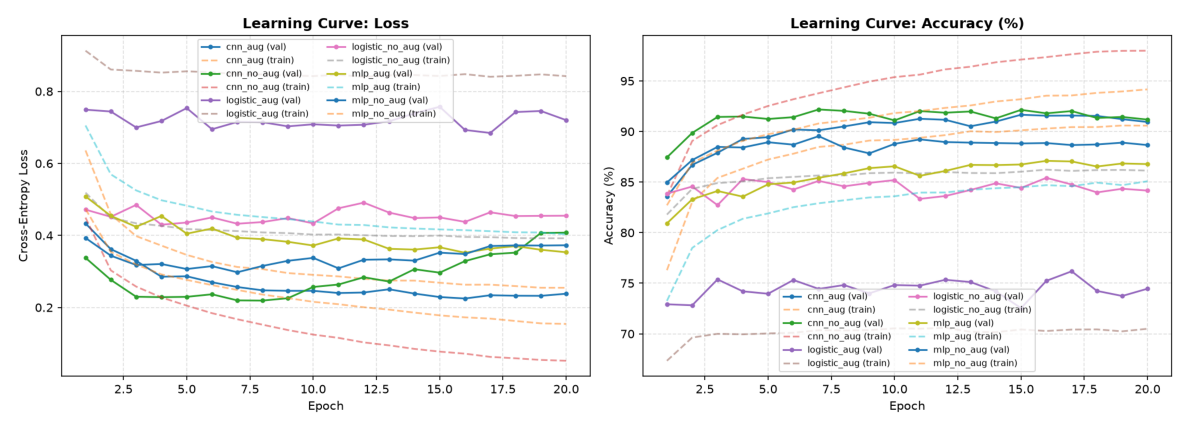

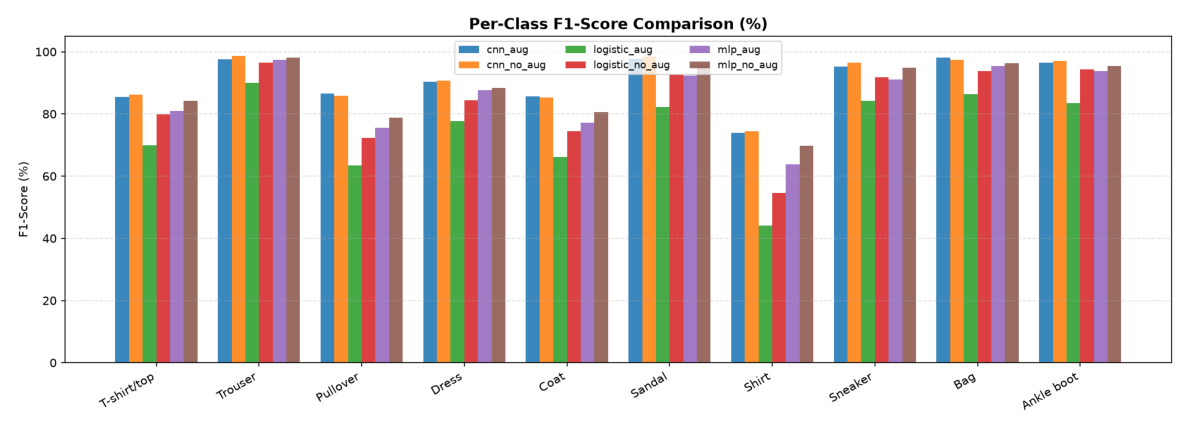

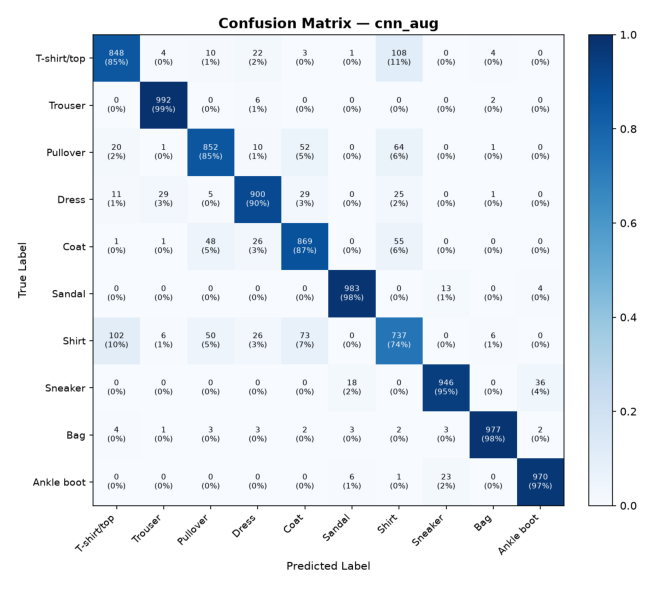

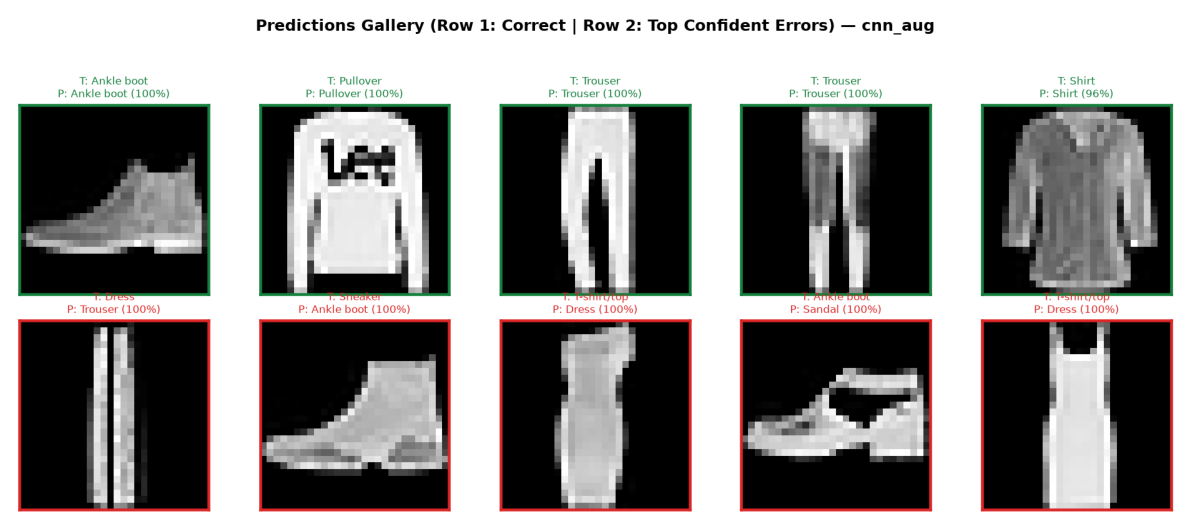


--- Learning Curves Riêng Từng Thí Nghiệm ---


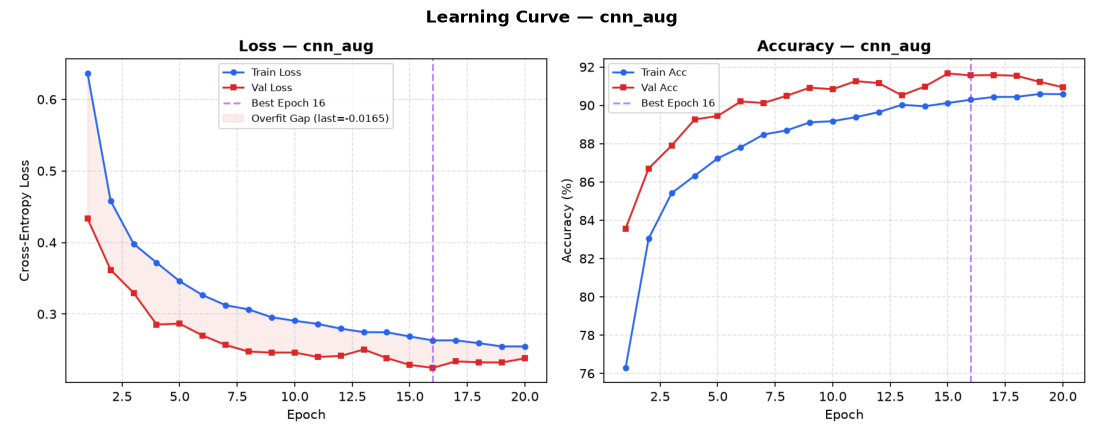

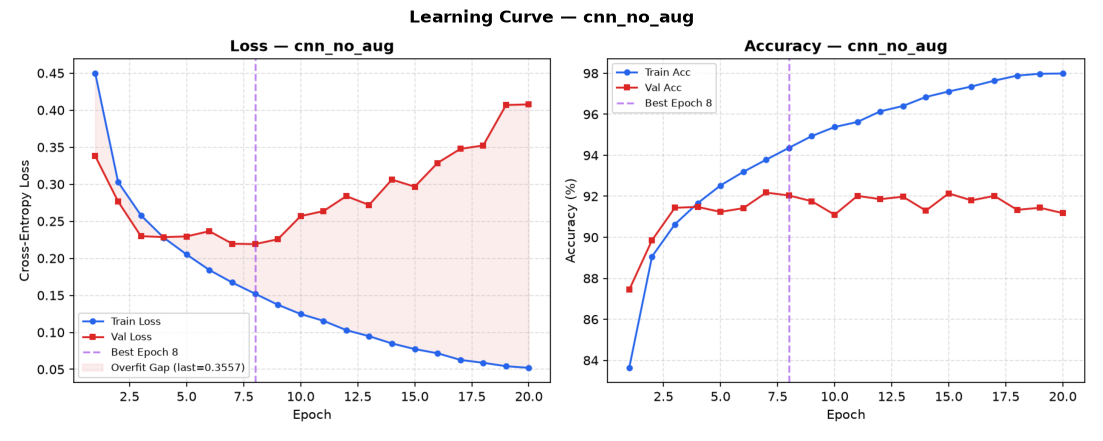

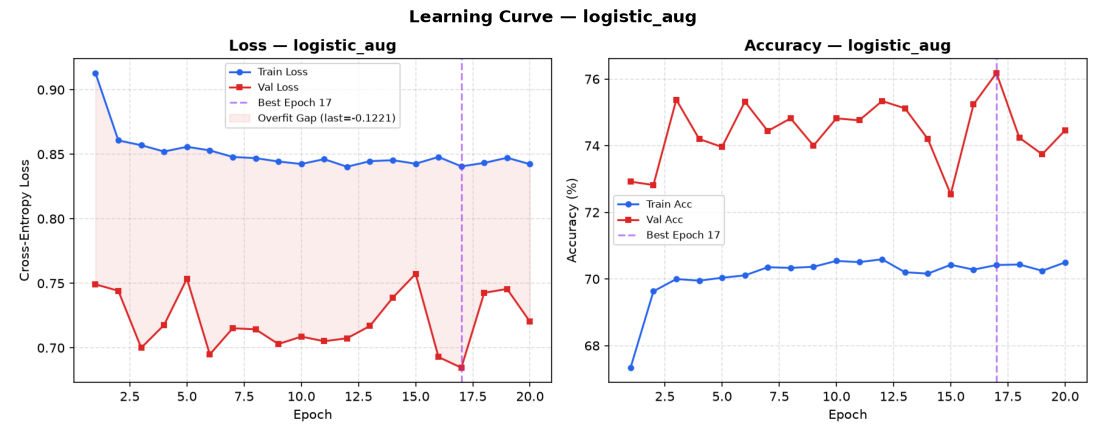

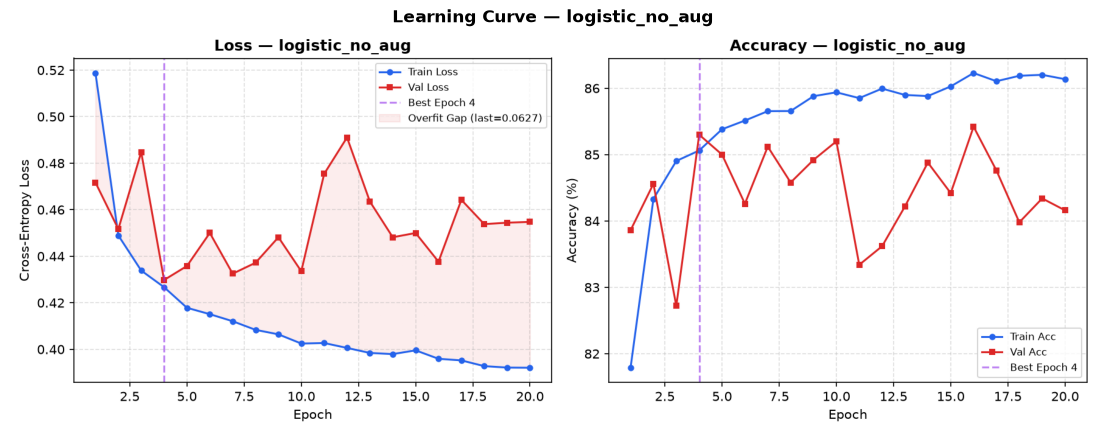

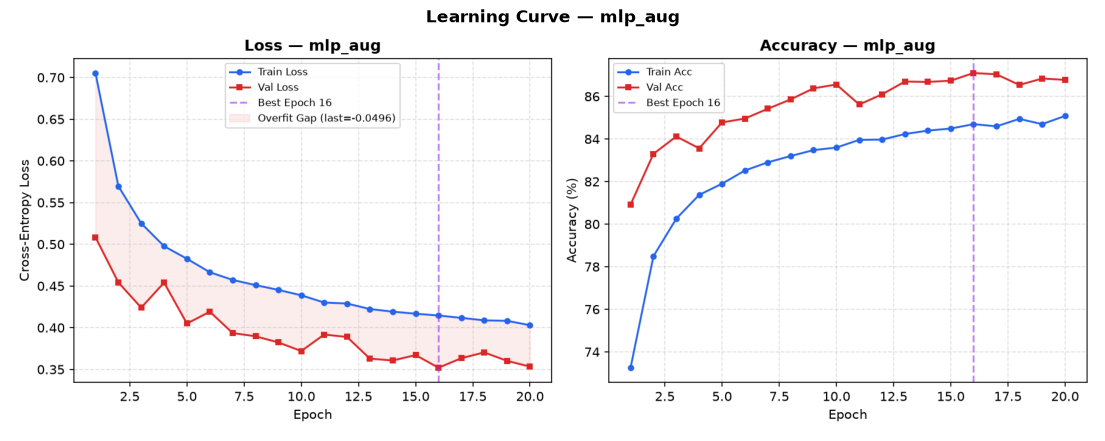

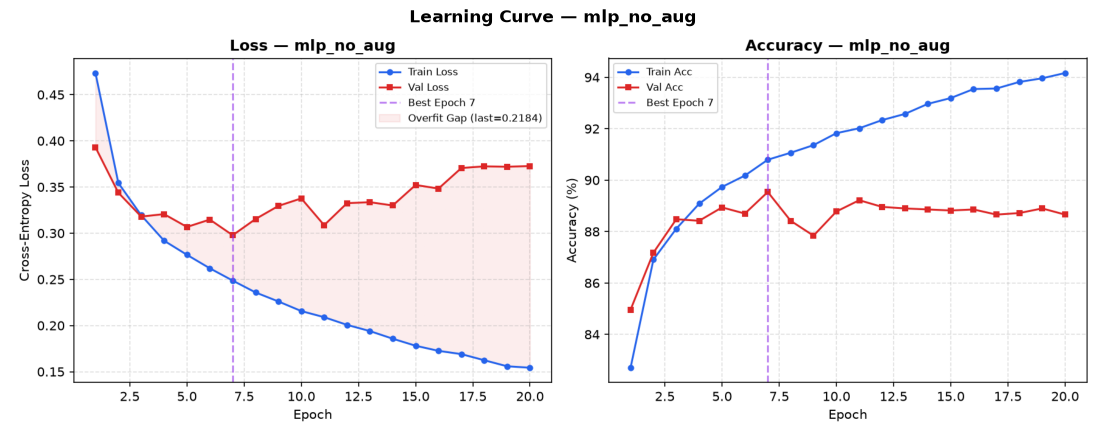

In [32]:
benchmark_out = lab1_eval.run_benchmark(
    experiments_dir=lab1_cfg.EXPERIMENT_DIR,
    test_loader=test_loader,
    device=lab1_cfg.DEVICE,
)

df_bench = pd.DataFrame(benchmark_out["benchmark_rows"])
v_objConsole.print(consoles.df_to_table(df_bench, title="PIPELINE 04: TEST BENCHMARK (3 MODELS x 2 CONFIGS)"))

# Hiển thị Top-5 cặp nhầm lẫn của mô hình CNN (aug & no_aug)
for eid in ["cnn_no_aug", "cnn_aug"]:
    confs = benchmark_out["experiments"][eid]["top_confusions"]
    df_conf = pd.DataFrame(confs)
    v_objConsole.print(consoles.df_to_table(df_conf, title=f"TOP CONFUSIONS — {eid.upper()}"))

# Hiển thị các biểu đồ đã xuất trong experiments/lab1/predictions/
for img_name in [
    "learning_curves_comparison.png",
    "per_class_f1_comparison.png",
    "confusion_matrix_cnn_aug.png",
    "predictions_gallery_cnn_aug.png",
]:
    p = lab1_cfg.PREDICTIONS_DIR / img_name
    if p.exists():
        fig, ax = plt.subplots(figsize=(12, 6))
        ax.imshow(Image.open(p))
        ax.axis("off")
        plt.tight_layout()
        plt.show()

# Hiển thị learning curve riêng từng thí nghiệm
print("\n--- Learning Curves Riêng Từng Thí Nghiệm ---")
for exp_sub in sorted(lab1_cfg.EXPERIMENT_DIR.iterdir()):
    lc_path = lab1_cfg.PREDICTIONS_DIR / f"learning_curve_{exp_sub.name}.png"
    if lc_path.exists():
        fig, ax = plt.subplots(figsize=(12, 4.5))
        ax.imshow(Image.open(lc_path))
        ax.set_title(f"Learning Curve — {exp_sub.name}", fontsize=12, fontweight="bold")
        ax.axis("off")
        plt.tight_layout()
        plt.show()

## 12. Pipeline 05: Suy Luận Mẫu & Benchmark Độ Trễ

Nạp độc lập checkpoint `best.pt` dưới `@torch.inference_mode()`, xuất phân phối xác suất Top-3 Softmax và đo tốc độ suy luận chuẩn (`batch_size = 1` & `32`).

In [19]:
bench_rows = []
for m_name in lab1_cfg.MODEL_NAMES:
    ckpt_p = lab1_cfg.EXPERIMENT_DIR / f"{m_name}_no_aug" / "best.pt"
    pred = lab1_infer.load_predictor(ckpt_p, device=lab1_cfg.DEVICE)
    lat = lab1_infer.benchmark_latency(pred, batch_sizes=(1, 32), warmup_runs=10, measure_runs=50)
    bench_rows.append((
        m_name.upper(),
        f"{lat[1]['checkpoint_size_kb']:.2f} KB",
        f"{lat[1]['mean_ms']:.3f} ms",
        f"{lat[32]['mean_ms']:.3f} ms",
        f"{lat[32]['samples_per_sec']:,.0f} img/s",
    ))

df_lat = pd.DataFrame(bench_rows, columns=["Mô hình", "Checkpoint Size", "Latency (BS=1)", "Latency (BS=32)", "Throughput (BS=32)"])
v_objConsole.print(consoles.df_to_table(df_lat, title="PIPELINE 05: INFERENCE LATENCY BENCHMARK"))

# Suy luận thử 1 mẫu Test trên cnn_aug
cnn_pred = lab1_infer.load_predictor(lab1_cfg.EXPERIMENT_DIR / "cnn_aug" / "best.pt", device=lab1_cfg.DEVICE)
sample_pil, sample_y = FashionMNIST(root=lab1_cfg.DATA_PATH, train=False, download=False)[18]
inf_res = lab1_infer.predict_single(cnn_pred, sample_pil)
df_inf = pd.DataFrame(
    [(r["class_id"], r["label"], f"{r['prob']*100:.2f}%") for r in inf_res["top3"]],
    columns=["Class ID", "Predicted Label", "Probability"],
)
v_objConsole.print(consoles.df_to_table(df_inf, title=f"SAMPLE #18 TOP-3 (TRUE: {eda_helpers.FASHION_CLASSES[sample_y]})"))

                       PIPELINE 05: INFERENCE LATENCY BENCHMARK                       
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ Mô hình  ┃ Checkpoint Size ┃ Latency (BS=1) ┃ Latency (BS=32) ┃ Throughput (BS=32) ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ LOGISTIC │ 95.89 KB        │ 0.360 ms       │ 0.345 ms        │ 92,724 img/s       │
│ MLP      │ 1289.59 KB      │ 0.531 ms       │ 0.624 ms        │ 51,271 img/s       │
│ CNN      │ 1250.82 KB      │ 0.949 ms       │ 1.042 ms        │ 30,723 img/s       │
└──────────┴─────────────────┴────────────────┴─────────────────┴────────────────────┘
                                   3 rows × 5 cols                                    

        SAMPLE #18 TOP-3 (TRUE: Bag)        
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Class ID ┃ Predicted Label ┃ Probability ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│        8 │ Bag             │ 99.99%      │
│        6 │ Shirt           │ 0.01%       │
│        0 │ T-shirt/top     │ 0.01%       │
└──────────┴─────────────────┴─────────────┘
              3 rows × 3 cols               